# Reinforcement Learning (PPO) with TorchRL

Proximal Policy Optimization (PPO) is a policy-gradient algorithm where a batch of data is being collected and directly consumed to train the policy to maximise the expected return given some proximality constraints. 

PPO is usually regarded as a fast and efficient method for online, on-policy reinforcement algorithm.

In [1]:
!pip install torchrl
!pip install "gymnasium[mujoco]"
!pip install tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 53.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.0/876.0 kB 26.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [torchrl]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 140.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 148.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 87.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [mujoco]


In [2]:
from collections import defaultdict

import matplotlib.pyplot as plt
import torch 
from tensordict.nn import TensorDictModule
from tensordict.nn.distributions import NormalParamExtractor
from torch import multiprocessing, nn

from torchrl.collectors import Collector
from torchrl.data.replay_buffers import ReplayBuffer
from torchrl.data.replay_buffers.samplers import SamplerWithoutReplacement
from torchrl.data.replay_buffers.storages import LazyTensorStorage

from torchrl.envs import (
    Compose,
    DoubleToFloat,
    ObservationNorm,
    StepCounter,
    TransformedEnv,
)

from torchrl.envs.libs.gym import GymEnv
from torchrl.modules import ProbabilisticActor, TanhNormal, ValueOperator
from torchrl.envs.utils import check_env_specs, ExplorationType, set_exploration_type
from torchrl.objectives import ClipPPOLoss
from torchrl.objectives.value import GAE
from tqdm import tqdm

/usr/local/lib/python3.13/dist-packages/torchrl/_utils.py:132: DeprecationWarning: TorchRL support for torch<2.13 (found torch 2.11.0+cu130) is deprecated and will be removed in v0.17. torch 2.11 and 2.12 remain supported until then for stacks that pin them, such as Isaac Lab 3.0. Upgrade to torch>=2.13 to silence this warning.
  warnings.warn(


## Define Hyperparameters

Set the hyperparameters for the algorithm. Depending on the resources available, one may choose to execute the policy on GPU or on another device. 

In [3]:
is_fork = multiprocessing.get_start_method() == 'fork'

device = (
    torch.device(0)
    if torch.cuda.is_available() and not is_fork
    else torch.device("cpu")
)

num_cells = 256 # number of cells in each layer i.e. output dim.
lr = 3e-4 # learning rate
max_grad_norm = 1.0

In [4]:
device

device(type='cuda', index=0)

## Data Collection parameters 

When collecting data, we can choose how big each batch will be by defining a `frames_per_batch` parameter, also define how many frames (such as the number of interactions with the simulator) we will allow ourselves to use. 

In [5]:
frames_per_batch = 1000
# For a complete training, bring the number of frames up tod 1M
total_frames = 10_000

## PPO parameters

In [6]:
sub_batch_size = 64
num_epochs = 10 # optimization steps per batch of data collected
clip_epsilon = (0.2) 
gamma = 0.99 # discount rate
lmbda = 0.95
entropy_eps = 1e-4

## Define an environment

In [7]:
import gymnasium as gym

base_env = GymEnv('InvertedDoublePendulum-v4', device=device)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [8]:
env = TransformedEnv(
    base_env,
    Compose(
        # normalize observations
        ObservationNorm(in_keys=['observation']),
        DoubleToFloat(),
        StepCounter(),
    ),
)

In [9]:
env.transform[0].init_stats(num_iter=1000, reduce_dim=0, cat_dim=0)
print("normalization constant shape:", env.transform[0].loc.shape)

normalization constant shape: torch.Size([11])


Let's see a concrete example using our transformed environment by looking at its specs. There are three specs to look at: `observation_spec` which defines what is to be expected when executing an action in the environment, `reward_spec` which indicates the reward domain and finally the `input_spec` (which contains the `action_spec`) and which represents everything an environment requires to execute a single step. 

In [10]:
print('observation_spec:', env.observation_spec)
print('reward_spec:', env.reward_spec)
print('input_spec:', env.input_spec)
print('action_spec (as defined by input_spec:', env.action_spec)

observation_spec: Composite(
    observation: UnboundedContinuous(
        shape=torch.Size([11]),
        space=ContinuousBox(
            low=Tensor(shape=torch.Size([11]), device=cuda:0, dtype=torch.float32, contiguous=True),
            high=Tensor(shape=torch.Size([11]), device=cuda:0, dtype=torch.float32, contiguous=True)),
        device=cuda:0,
        dtype=torch.float32,
        domain=continuous),
    step_count: BoundedDiscrete(
        shape=torch.Size([1]),
        space=ContinuousBox(
            low=Tensor(shape=torch.Size([1]), device=cuda:0, dtype=torch.int64, contiguous=True),
            high=Tensor(shape=torch.Size([1]), device=cuda:0, dtype=torch.int64, contiguous=True)),
        device=cuda:0,
        dtype=torch.int64,
        domain=discrete),
    device=cuda:0,
    shape=torch.Size([]),
    data_cls=None)
reward_spec: UnboundedContinuous(
    shape=torch.Size([1]),
    space=ContinuousBox(
        low=Tensor(shape=torch.Size([1]), device=cuda:0, dtype=torch.fl

In [11]:
check_env_specs(env)

2026-11-13 07:32:02,434 [torchrl][INFO]    check_env_specs succeeded! [END]


In [12]:
rollout = env.rollout(3)
print('rollout of three steps:', rollout)
print('Shape of the rollout TensorDict:', rollout.batch_size)

rollout of three steps: TensorDict(batch_size=[3], device=cuda:0, fields={
    action: f32[1],
    done: bool[1],
    next: {
        done: bool[1],
        observation: f32[11],
        reward: f32[1],
        step_count: i64[1],
        terminated: bool[1],
        truncated: bool[1]},
    observation: f32[11],
    step_count: i64[1],
    terminated: bool[1],
    truncated: bool[1]})
Shape of the rollout TensorDict: torch.Size([3])


## Policy 

PPO utilizes a stochastic policy to handle exploration. This means that the neural network will have to output the parameters of a distribution, rather than a single value corresponding to the action taken. 

We design the policy in three steps:
1. Define a neural network `D_obs` -> `2 * D_action`. Indeed, our `loc` (mu) and `scale` (sigma) both have dimension `D_action`.
2. Append a `NormalParamExtractor` to extract a location and a scale (for example, splits the input in two equal parts and applies a positive transformation to the scale parameters).
3. Create a probabilistic `TensorDictModule` that can generate this distribution and sample from it. 

In [13]:
action_net = nn.Sequential(
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(2 * env.action_spec.shape[-1], device=device),
    NormalParamExtractor()
)

action_net

Sequential(
  (0): LazyLinear(in_features=0, out_features=256, bias=True)
  (1): Tanh()
  (2): LazyLinear(in_features=0, out_features=256, bias=True)
  (3): Tanh()
  (4): LazyLinear(in_features=0, out_features=256, bias=True)
  (5): Tanh()
  (6): LazyLinear(in_features=0, out_features=2, bias=True)
  (7): NormalParamExtractor(
    (scale_mapping): biased_softplus()
  )
)

In [14]:
policy_module = TensorDictModule(
    action_net, in_keys=['observation'], out_keys=['loc', 'scale']
)

Build a distribution out of the location and scale of our normal distribution. To do so, we instruct the `ProbabilisticActor` class to build a `TanhNormal` out of the location and scale parameters. We also provide the minimum and maximum values of this distribution, which we gather from the environment specs. 

In [15]:
policy_module = ProbabilisticActor(
    module=policy_module,
    spec=env.action_spec,
    in_keys=['loc', 'scale'],
    distribution_class=TanhNormal,
    distribution_kwargs={
        'low': env.action_spec_unbatched.space.low,
        'high': env.action_spec_unbatched.space.high,
    },
    return_log_prob=True,
)

In [16]:
policy_module

ProbabilisticActor(
    module=ModuleList(
      (0): TensorDictModule(
          module=Sequential(
            (0): LazyLinear(in_features=0, out_features=256, bias=True)
            (1): Tanh()
            (2): LazyLinear(in_features=0, out_features=256, bias=True)
            (3): Tanh()
            (4): LazyLinear(in_features=0, out_features=256, bias=True)
            (5): Tanh()
            (6): LazyLinear(in_features=0, out_features=2, bias=True)
            (7): NormalParamExtractor(
              (scale_mapping): biased_softplus()
            )
          ),
          in_keys=['observation'],
          out_keys=['loc', 'scale'])
      (1): SafeProbabilisticModule(
          in_keys=['loc', 'scale'],
          out_keys=['action', 'action_log_prob'],
          distribution_class=<class 'torchrl.modules.distributions.continuous.TanhNormal'>, 
          distribution_kwargs={'low': tensor([-1.], device='cuda:0'), 'high': tensor([1.], device='cuda:0')}),
          default_interactio

## Value Network

The value network is a crucial component of the PPO algorithm, even though it won't be used at inference time. This module will read the observations and return an estimation of the discounted return for the following trajectory. This allows us to amortize learning by relying on the some utility estimation that is learned on-the-fly during training. Our value network shares the same structure as the policy. 

In [17]:
value_net = nn.Sequential(
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(num_cells, device=device),
    nn.Tanh(),
    nn.LazyLinear(1, device=device)
)

value_module = ValueOperator(
    module=value_net,
    in_keys=['observation']
)

In [18]:
value_module

ValueOperator(
    module=Sequential(
      (0): LazyLinear(in_features=0, out_features=256, bias=True)
      (1): Tanh()
      (2): LazyLinear(in_features=0, out_features=256, bias=True)
      (3): Tanh()
      (4): LazyLinear(in_features=0, out_features=256, bias=True)
      (5): Tanh()
      (6): LazyLinear(in_features=0, out_features=1, bias=True)
    ),
    in_keys=['observation'],
    out_keys=['state_value'])

#### Run a dummy forward pass to initialize the Lazy modules (strictly required!)

In [19]:
out_policy = policy_module(env.reset())
out_value = value_module(env.reset())

print('Running policy:', out_policy)
print('Running value:', out_value)

Running policy: TensorDict(batch_size=[], device=cuda:0, fields={
    action: f32[1],
    action_log_prob: f32[],
    done: bool[1],
    loc: f32[1],
    observation: f32[11],
    scale: f32[1],
    step_count: i64[1],
    terminated: bool[1],
    truncated: bool[1]})
Running value: TensorDict(batch_size=[], device=cuda:0, fields={
    done: bool[1],
    observation: f32[11],
    state_value: f32[1],
    step_count: i64[1],
    terminated: bool[1],
    truncated: bool[1]})


## Model mode
We keep the policy and value modules in eval mode during PPO training.

In [20]:
policy_module.eval()
value_module.eval()

ValueOperator(
    module=Sequential(
      (0): Linear(in_features=11, out_features=256, bias=True)
      (1): Tanh()
      (2): Linear(in_features=256, out_features=256, bias=True)
      (3): Tanh()
      (4): Linear(in_features=256, out_features=256, bias=True)
      (5): Tanh()
      (6): Linear(in_features=256, out_features=1, bias=True)
    ),
    in_keys=['observation'],
    out_keys=['state_value'])

## Data Collector

TorchRL provides the `Collector` construction API for the execution strategies in ref_collectors. Collectors execute three operations: reset an environment, compute an action given the latest observation, execute a step in the environment, and repeat the last two steps until the environment signals a stop (or reaches a terminal state).

In [21]:
collector = Collector(
    env,
    policy_module, 
    frames_per_batch=frames_per_batch,
    total_frames=total_frames,
    split_trajs=False,
    device=device,
    auto_register_policy_transforms=True,
)

collector

Collector(
    env=TransformedEnv(
        env=GymEnv(env=InvertedDoublePendulum-v4, batch_size=torch.Size([]), device=cuda:0),
        transform=Compose(
                ObservationNorm(keys=['observation']),
                DoubleToFloat(in_keys=['observation'], out_keys=['observation'], in_keys_inv=[], out_keys_inv=[]),
                StepCounter(keys=[]),
                InitTracker(keys=[]))),
    policy=ProbabilisticActor(
        module=ModuleList(
          (0): TensorDictModule(
              module=Sequential(
                (0): Linear(in_features=11, out_features=256, bias=True)
                (1): Tanh()
                (2): Linear(in_features=256, out_features=256, bias=True)
                (3): Tanh()
                (4): Linear(in_features=256, out_features=256, bias=True)
                (5): Tanh()
                (6): Linear(in_features=256, out_features=2, bias=True)
                (7): NormalParamExtractor(
                  (scale_mapping): biased_softplus()


## Replay Buffer

Replay Buffer are a common building piece of off-policy RL algorithms. In on-policy contexts, a replay buffer is refilled every time a batch of data is collected, and its data is repeatedly consumed for a certain number of epochs. 

`ReplayBuffer` takes as arguments the components of the buffer: a storage, a writer, and possibly some transforms. Only the storage (which indicates the replay buffer capacity) is mandatory. We also specify a sampler without repetition to avoid sampling the same item multiple times in one epoch.   

In [22]:
replay_buffer = ReplayBuffer(
    storage=LazyTensorStorage(max_size=frames_per_batch),
    sampler=SamplerWithoutReplacement(),
)

replay_buffer

ReplayBuffer(
    storage=LazyTensorStorage(
        data=<empty>, 
        shape=None, 
        len=0, 
        max_size=1000), 
    sampler=SamplerWithoutReplacement( 0.0000% sampled), 
    writer=RoundRobinWriter(cursor=0, full_storage=False), 
    batch_size=None, 
    collate_fn=<function _collate_id at 0x7e0c0098c720>)

## Advantage Estimation

PPO requires some 'advantage estimation' to be computed. In short, an advantage is a value that reflects and expectancy over the return value while dealing with the bias/variance tradeoff. To compute the advantage, one just needs to (1) build the advantage module, which utilizes our value operator, and (2) pass each batch of data through it before each epoch. The GAE module `'value_target'` is a gradient-free tensor that represents the empirical value that the value network should represent with the input observation. Both of these will be used by `ClipPPOLoss` to return the policy and value losses. 

In [23]:
advantage_module = GAE(
    gamma=gamma, lmbda=lmbda, value_network=value_module, average_gae=True
)

advantage_module

GAE(
    in_keys=['observation', ('next', 'reward'), ('next', 'done'), ('next', 'terminated'), ('next', 'observation')],
    out_keys=['advantage', 'value_target'])

## Loss Function

The PPO loss can be directly imported from TorchRL for convenience using the `ClipPPOLoss` class. 

In [24]:
loss_module = ClipPPOLoss(
    actor_network=policy_module,
    critic_network=value_module,
    clip_epsilon=clip_epsilon,
    entropy_bonus=bool(entropy_eps),
    entropy_coeff=entropy_eps,
    critic_coeff=1.0,
    loss_critic_type='smooth_l1'
)

optim = torch.optim.Adam(loss_module.parameters(), lr)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optim, total_frames // frames_per_batch, 0.0
)

## Training Loop

We now have all the pieces needed to code our training loop. The steps include:

* Collect data
    * Compute advantage
        * Loop over the collected to compute loss values
        * Back propagate
        * Optimize
        * Repeat
    * Repeat
* Repeat

In [25]:
logs = defaultdict(list)
pbar = tqdm(total=total_frames)
eval_str = ""

# We iterate over the collector until it reaches the total number of frames it was
# designed to collect:
for i, tensordict_data in enumerate(collector):
    # we now have a batch of data to work with. Let's learn something from it.
    for _ in range(num_epochs):
        # We'll need an "advantage" signal to make PPO work.
        # We re-compute it at each epoch as its value depends on the value
        # network which is updated in the inner loop.
        advantage_module(tensordict_data)
        data_view = tensordict_data.reshape(-1)
        replay_buffer.extend(data_view.cpu())
        for _ in range(frames_per_batch // sub_batch_size):
            subdata = replay_buffer.sample(sub_batch_size)
            loss_vals = loss_module(subdata.to(device))
            loss_value = (
                loss_vals["loss_objective"]
                + loss_vals["loss_critic"]
                + loss_vals["loss_entropy"]
            )

            # Optimization: backward, grad clipping and optimization step
            loss_value.backward()
            # this is not strictly mandatory but it's good practice to keep
            # your gradient norm bounded
            torch.nn.utils.clip_grad_norm_(loss_module.parameters(), max_grad_norm)
            optim.step()
            optim.zero_grad()

    logs["reward"].append(tensordict_data["next", "reward"].mean().item())
    pbar.update(tensordict_data.numel())
    cum_reward_str = (
        f"average reward={logs['reward'][-1]: 4.4f} (init={logs['reward'][0]: 4.4f})"
    )
    logs["step_count"].append(tensordict_data["step_count"].max().item())
    stepcount_str = f"step count (max): {logs['step_count'][-1]}"
    logs["lr"].append(optim.param_groups[0]["lr"])
    lr_str = f"lr policy: {logs['lr'][-1]: 4.4f}"
    if i % 10 == 0:
        # We evaluate the policy once every 10 batches of data.
        # Evaluation is rather simple: execute the policy without exploration
        # (take the expected value of the action distribution) for a given
        # number of steps (1000, which is our ``env`` horizon).
        # The ``rollout`` method of the ``env`` can take a policy as argument:
        # it will then execute this policy at each step.
        # The context manager below changes the action-selection mode only; it
        # does not switch the module between train and eval modes.
        with set_exploration_type(ExplorationType.DETERMINISTIC), torch.no_grad():
            # execute a rollout with the trained policy
            eval_rollout = env.rollout(1000, policy_module)
        logs["eval reward"].append(eval_rollout["next", "reward"].mean().item())
        logs["eval reward (sum)"].append(eval_rollout["next", "reward"].sum().item())
        logs["eval step_count"].append(eval_rollout["step_count"].max().item())
        eval_str = (
            f"eval cumulative reward: {logs['eval reward (sum)'][-1]: 4.4f} "
            f"(init: {logs['eval reward (sum)'][0]: 4.4f}), "
            f"eval step-count: {logs['eval step_count'][-1]}"
        )
        del eval_rollout
    pbar.set_description(", ".join([eval_str, cum_reward_str, stepcount_str, lr_str]))

    # We're also using a learning rate scheduler. Like the gradient clipping,
    # this is a nice-to-have but nothing necessary for PPO to work.
    scheduler.step()

  0%|          | 0/10000 [00:00<?, ?it/s]

2026-11-13 07:32:06,400 [torchrl][INFO]    Initialized LazyTensorStorage with torch.Size([1000]) shape [END]


eval cumulative reward:  129.7236 (init:  129.7236), eval step-count: 13, average reward= 9.2544 (init= 9.0874), step count (max): 35, lr policy:  0.0000: 100%|██████████| 10000/10000 [00:42<00:00, 241.04it/s]

## Results

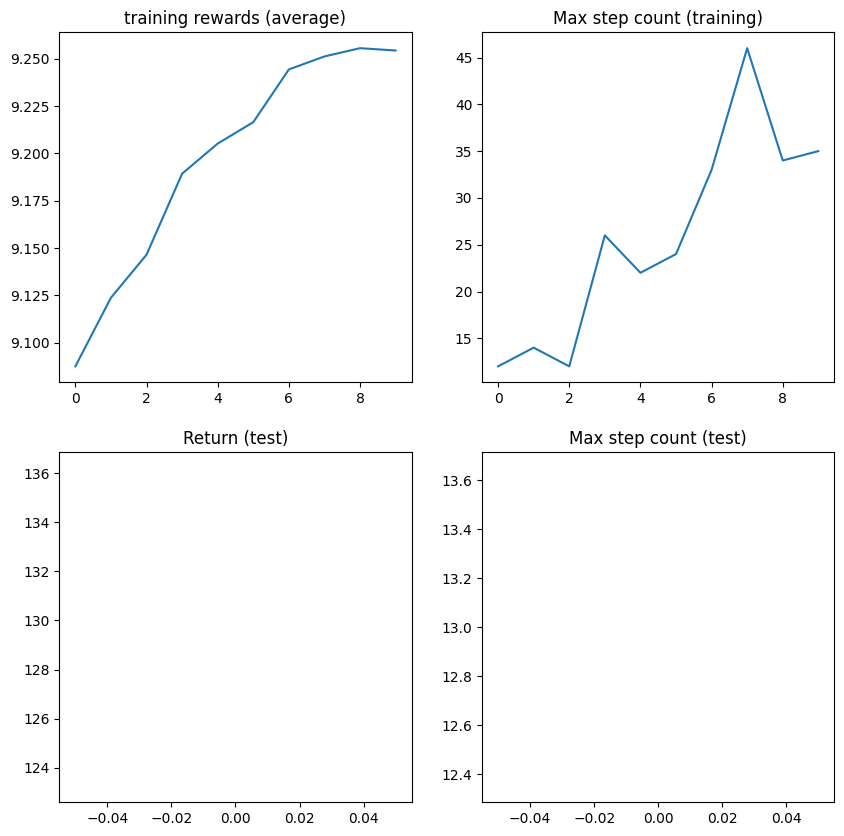

In [26]:
plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.plot(logs["reward"])
plt.title("training rewards (average)")
plt.subplot(2, 2, 2)
plt.plot(logs["step_count"])
plt.title("Max step count (training)")
plt.subplot(2, 2, 3)
plt.plot(logs["eval reward (sum)"])
plt.title("Return (test)")
plt.subplot(2, 2, 4)
plt.plot(logs["eval step_count"])
plt.title("Max step count (test)")
plt.show()